# DTUMOS Seoul Taxi Multi-Agent Orchestrator
This notebook scaffolds 3-5 Ollama-driven agents that coordinate to run DTUMOS (Seoul OSRM) simulations, analyze supply vs. demand, and propose interventions using structured outputs. Ensure the local OSRM server is running at http://127.0.0.1:5000 with the Seoul graph before executing the pipeline.

In [ ]:
from __future__ import annotations
import sys
import json
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional
from datetime import datetime

import pandas as pd
from pydantic import BaseModel, Field
import ollama

MODEL_NAME = "llama3.1:latest"

def find_dtumos_root() -> Path:
    here = Path().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "module").exists():
            return candidate
    raise RuntimeError("Could not find dtumos root containing 'module' directory")

DTUMOS_ROOT = find_dtumos_root()
if str(DTUMOS_ROOT) not in sys.path:
    sys.path.append(str(DTUMOS_ROOT))

DATA_DIR = DTUMOS_ROOT / "data"
AGENTS_DATA_DIR = DATA_DIR / "agents"
EXPORT_DIR = AGENTS_DATA_DIR / "exports"
PASSENGER_CSV = AGENTS_DATA_DIR / "passenger" / "passenger_data.csv"
VEHICLE_CSV = AGENTS_DATA_DIR / "vehicle" / "vehicle_data.csv"
OSRM_URL = "http://127.0.0.1:5000"

print(f"DTUMOS root: {DTUMOS_ROOT}")

DTUMOS root: /Users/august/Documents/Projects/urban_mobility_digital_twin/thirdparty/dtumos


In [2]:
from module.simulator_helper import (
    base_configs,
    get_preprocessed_seoul_data,
    generate_path_to_save,
    generate_simulation_result_json,
    )
from module.simulator import Simulator
from module.services.disabled_callTaxi.extract_data import extract_main

def build_config(additional_path: str = "scenario_base", overrides: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    cfg = base_configs.copy()
    cfg["additional_path"] = additional_path
    cfg.setdefault("time_range", [360, 1440])
    cfg.setdefault("dispatch_mode", "in_order")
    cfg.setdefault("matrix_mode", "street_distance")
    if overrides:
        cfg.update({k: v for k, v in overrides.items() if v is not None})
    # Leave cfg['path'] as default (None) so Simulator can manage save paths uniquely.
    return cfg

default_configs = build_config()
default_configs

{'target_region': '서울 대한민국',
 'problem': 'disabledCalltaxi',
 'relocation_region': 'seoul',
 'path': None,
 'additional_path': 'scenario_base',
 'time_range': [360, 1440],
 'fail_time': 30,
 'add_board_time': 10,
 'add_disembark_time': 10,
 'matrix_mode': 'street_distance',
 'dispatch_mode': 'in_order',
 'eta_model': None,
 'view_operation_graph': True}

In [3]:
@dataclass
class SimulationState:
    configs: Dict[str, Any] = field(default_factory=lambda: build_config())
    passengers: Optional[pd.DataFrame] = None
    vehicles: Optional[pd.DataFrame] = None
    last_run_path: Optional[Path] = None
    last_results: Dict[str, Any] = field(default_factory=dict)
    conversation: List[Dict[str, str]] = field(default_factory=list)

state = SimulationState()
state.configs

{'target_region': '서울 대한민국',
 'problem': 'disabledCalltaxi',
 'relocation_region': 'seoul',
 'path': None,
 'additional_path': 'scenario_base',
 'time_range': [360, 1440],
 'fail_time': 30,
 'add_board_time': 10,
 'add_disembark_time': 10,
 'matrix_mode': 'street_distance',
 'dispatch_mode': 'in_order',
 'eta_model': None,
 'view_operation_graph': True}

## Structured output schemas
Each agent responds with a JSON object validated by Pydantic. Flags indicate whether to trigger DTUMOS functions (e.g., run simulation) and what parameters to use.

In [4]:
class DataCuratorPlan(BaseModel):
    prepare_baseline: bool = True
    use_existing_csv: bool = True
    passenger_csv: Optional[str] = str(PASSENGER_CSV)
    vehicle_csv: Optional[str] = str(VEHICLE_CSV)
    run_extract_main: bool = False
    operation_csv: Optional[str] = None
    override_time_range: Optional[List[int]] = Field(None, description="Minutes from day start [start, end]")
    override_dispatch_mode: Optional[str] = Field(None, description="in_order|optimization")
    override_matrix_mode: Optional[str] = Field(None, description="street_distance|ETA|haversine_distance")
    passenger_increase_ratio: Optional[float] = Field(None, description=">1 to scale up demand")
    taxi_schedule_multiplier: Optional[float] = Field(None, description=">1 to add vehicles")
    notes: Optional[str] = None

class OpsSimPlan(BaseModel):
    run_simulation: bool = True
    dispatch_mode: Optional[str] = None
    matrix_mode: Optional[str] = None
    time_range: Optional[List[int]] = None
    fail_time: Optional[int] = None
    add_board_time: Optional[int] = None
    add_disembark_time: Optional[int] = None
    notes: Optional[str] = None

class SupplyDemandPlan(BaseModel):
    analyze_outputs: bool = True
    focus_hours: Optional[List[int]] = None
    metrics: List[str] = Field(default_factory=lambda: ["failure_rate", "wait_time", "idle_vs_service"])
    notes: Optional[str] = None

class InterventionPlan(BaseModel):
    propose_changes: bool = True
    configs_patch: Dict[str, Any] = Field(default_factory=dict)
    trigger_rerun: bool = False
    notes: Optional[str] = None

class OrchestratorPlan(BaseModel):
    next_action: str = Field("summarize", description="What to do next")
    approve_rerun: bool = False
    stop: bool = False
    notes: Optional[str] = None

In [5]:
def run_agent(name: str, system_prompt: str, user_prompt: str, schema_model: BaseModel.__class__, temperature: float = 0.0, state: SimulationState | None = None, log_label: str | None = None):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    response = ollama.chat(
        model=MODEL_NAME,
        messages=messages,
        options={"temperature": temperature},
        format=schema_model.model_json_schema(),
    )
    raw = response["message"]["content"]
    parsed = schema_model.model_validate_json(raw)
    if state is not None:
        label = log_label or name
        # Store both the raw JSON string and the parsed object for nicer display later.
        append_conv(state, label, json.dumps(json.loads(raw), indent=2, ensure_ascii=False))
    return parsed

def append_conv(state: SimulationState, role: str, content: str):
    state.conversation.append({"role": role, "content": content})

In [ ]:
def rescale_vehicles(vehicles: pd.DataFrame, target_size: int) -> pd.DataFrame:
    if vehicles is None or len(vehicles) == 0 or target_size <= 0:
        return vehicles
    base = vehicles.reset_index(drop=True)
    n = len(base)
    if target_size == n:
        return base
    if target_size < n:
        sampled = base.sample(n=target_size, replace=False, random_state=42).reset_index(drop=True)
        return sampled
    # target_size > n: upsample with replacement, ensure unique vehicle_id
    extra = base.sample(n=target_size - n, replace=True, random_state=42).reset_index(drop=True)
    extra['vehicle_id'] = extra['vehicle_id'].astype(str) + "_dup" + (extra.index + 1).astype(str)
    return pd.concat([base, extra], ignore_index=True)


def rescale_passengers(passengers: pd.DataFrame, ratio: float) -> pd.DataFrame:
    if passengers is None or len(passengers) == 0 or ratio <= 0:
        return passengers
    base = passengers.sort_values('ride_time').reset_index(drop=True)
    n = len(base)
    target = max(1, int(round(n * ratio)))
    if target == n:
        return base
    if target < n:
        scaled = base.sample(n=target, replace=False, random_state=42).sort_values('ride_time').reset_index(drop=True)
        scaled['ID'] = scaled.index
        return scaled
    # target > n: upsample with replacement and ensure unique IDs
    extra = base.sample(n=target - n, replace=True, random_state=42).reset_index(drop=True)
    extra['ID'] = range(n, n + len(extra))
    scaled = pd.concat([base, extra], ignore_index=True).sort_values('ride_time').reset_index(drop=True)
    scaled['ID'] = scaled.index
    return scaled


def normalize_vehicle_ids(df: pd.DataFrame | None) -> pd.DataFrame | None:
    if df is None or 'vehicle_id' not in df.columns:
        return df
    def _to_native(x):
        try:
            return int(x)
        except Exception:
            return str(x)
    normalized = df.copy()
    normalized['vehicle_id'] = normalized['vehicle_id'].apply(_to_native)
    return normalized


def apply_data_curator(plan: DataCuratorPlan, state: SimulationState) -> Dict[str, Any]:
    cfg = state.configs.copy()
    if plan.override_time_range: cfg["time_range"] = plan.override_time_range
    if plan.override_dispatch_mode: cfg["dispatch_mode"] = plan.override_dispatch_mode
    if plan.override_matrix_mode: cfg["matrix_mode"] = plan.override_matrix_mode
    if plan.passenger_increase_ratio: cfg["passenger_increase_ratio"] = plan.passenger_increase_ratio
    if plan.taxi_schedule_multiplier: cfg["taxi_schedule_multiplier"] = plan.taxi_schedule_multiplier

    passengers = None
    vehicles = None
    if plan.prepare_baseline and plan.use_existing_csv:
        passengers = pd.read_csv(plan.passenger_csv)
        vehicles = pd.read_csv(plan.vehicle_csv)
        passengers, vehicles = get_preprocessed_seoul_data(passengers, vehicles)
    elif plan.run_extract_main:
        if not plan.operation_csv:
            raise ValueError("operation_csv required when run_extract_main is True")
        operation_record = pd.read_csv(plan.operation_csv)
        passengers, vehicles, _ = extract_main(operation_record, cfg)

    # Do not pre-create save_path; let Simulator manage unique folders.
    state.passengers, state.vehicles, state.configs = passengers, vehicles, cfg
    state.last_run_path = None
    summary = {
        "passengers": 0 if passengers is None else len(passengers),
        "vehicles": 0 if vehicles is None else len(vehicles),
        "dispatch_mode": cfg.get("dispatch_mode"),
        "matrix_mode": cfg.get("matrix_mode"),
        "time_range": cfg.get("time_range"),
    }
    state.last_results["data_curator"] = summary
    return summary

def run_ops_sim(plan: OpsSimPlan, state: SimulationState) -> Dict[str, Any]:
    if not plan.run_simulation:
        return {"skipped": True}
    if state.passengers is None or state.vehicles is None:
        raise RuntimeError("Passengers/Vehicles missing. Run Data Curator first.")
    cfg = state.configs.copy()
    if plan.dispatch_mode: cfg["dispatch_mode"] = plan.dispatch_mode
    if plan.matrix_mode: cfg["matrix_mode"] = plan.matrix_mode
    if plan.time_range: cfg["time_range"] = plan.time_range
    if plan.fail_time: cfg["fail_time"] = plan.fail_time
    if plan.add_board_time: cfg["add_board_time"] = plan.add_board_time
    if plan.add_disembark_time: cfg["add_disembark_time"] = plan.add_disembark_time
    state.configs = cfg

    # Ensure vehicle IDs are JSON-serializable (avoid numpy int64).
    vehicles_native = normalize_vehicle_ids(state.vehicles)
    state.vehicles = vehicles_native

    scene = Simulator(passengers=state.passengers, vehicles=state.vehicles, configs=cfg)
    scene.run()
    # Simulator sets configs['save_path']; capture it for downstream steps.
    state.last_run_path = Path(scene.configs["save_path"])
    sim_summary = {"save_path": scene.configs.get("save_path"), "time_range": cfg.get("time_range") }
    state.last_results["ops_sim"] = sim_summary
    return sim_summary

def analyze_supply_demand(plan: SupplyDemandPlan, state: SimulationState) -> Dict[str, Any]:
    if not plan.analyze_outputs:
        return {"skipped": True}
    if state.last_run_path is None:
        raise RuntimeError("No simulation artifacts found. Run Ops Simulator first.")
    record_path = state.last_run_path / "record.csv"
    trip_path = state.last_run_path / "trip.json"
    passenger_path = state.last_run_path / "passenger_marker.json"
    records = pd.read_csv(record_path) if record_path.exists() else None
    trip = pd.read_json(trip_path) if trip_path.exists() else None
    passengers = pd.read_json(passenger_path) if passenger_path.exists() else None
    summary: Dict[str, Any] = {}
    if records is not None:
        summary["failures"] = int(records["fail_passenger_cnt"].max())
        summary["avg_waiting"] = float(records.get("average_waiting_time", pd.Series([0])).mean()) if "average_waiting_time" in records else None
        summary["waiting_peak"] = int(records["waiting_passenger_cnt"].max())
    if trip is not None:
        summary["trip_count"] = len(trip)
    if passengers is not None:
        summary["passenger_markers"] = len(passengers)
    state.last_results["analysis"] = summary
    return summary

def apply_intervention(plan: InterventionPlan, state: SimulationState) -> Dict[str, Any]:
    if not plan.propose_changes and not plan.configs_patch:
        return {"skipped": True}
    cfg = state.configs.copy()
    cfg.update(plan.configs_patch)

    # Fleet scaling
    fleet_size = cfg.get("fleet_size") or cfg.get("taxi_schedule_multiplier")
    if fleet_size and state.vehicles is not None and len(state.vehicles) > 0:
        if isinstance(fleet_size, (int, float)) and fleet_size > 0:
            target = int(round(fleet_size)) if fleet_size > 10 else int(round(fleet_size * len(state.vehicles)))
            target = max(1, target)
            orig = len(state.vehicles)
            state.vehicles = rescale_vehicles(state.vehicles, target)
            cfg["taxi_schedule_multiplier"] = target / orig

    # Demand scaling
    demand_scaling = cfg.get("demand_scaling") or cfg.get("passenger_increase_ratio")
    if demand_scaling and state.passengers is not None and len(state.passengers) > 0:
        if isinstance(demand_scaling, (int, float)) and demand_scaling > 0:
            state.passengers = rescale_passengers(state.passengers, demand_scaling)
            cfg["passenger_increase_ratio"] = float(demand_scaling)

    state.configs = cfg
    summary = {"configs_patch": plan.configs_patch}
    if plan.trigger_rerun:
        rerun_plan = OpsSimPlan(run_simulation=True)
        summary["rerun"] = run_ops_sim(rerun_plan, state)
    state.last_results["intervention"] = summary
    return summary


def summarize_round(result: Dict[str, Any], state: SimulationState) -> Dict[str, Any]:
    """Snapshot of configs and metrics for export."""
    cfg_snapshot = json.loads(json.dumps(state.configs, default=str))
    passengers = 0 if state.passengers is None else len(state.passengers)
    vehicles = 0 if state.vehicles is None else len(state.vehicles)
    return {
        "configs": cfg_snapshot,
        "passengers": passengers,
        "vehicles": vehicles,
        "analysis": result.get("analysis", {}),
        "simulation": result.get("simulation", {}),
        "intervention": result.get("intervention", {}),
    }


def compute_impact(current: Dict[str, Any], baseline: Dict[str, Any]) -> Dict[str, Any]:
    impacts: Dict[str, Any] = {}
    b_pass = baseline.get("passengers") or 0
    b_veh = baseline.get("vehicles") or 0
    impacts["passenger_delta"] = current.get("passengers", 0) - b_pass
    impacts["vehicle_delta"] = current.get("vehicles", 0) - b_veh
    impacts["passenger_ratio"] = (current.get("passengers", 0) / b_pass) if b_pass else None
    impacts["vehicle_ratio"] = (current.get("vehicles", 0) / b_veh) if b_veh else None
    for metric in ["failures", "avg_waiting", "waiting_peak", "trip_count", "passenger_markers"]:
        base_val = baseline.get("analysis", {}).get(metric)
        cur_val = current.get("analysis", {}).get(metric)
        if base_val is not None and cur_val is not None:
            impacts[f"{metric}_delta"] = cur_val - base_val
    return impacts


def export_round(round_idx: int, result: Dict[str, Any], state: SimulationState, baseline: Dict[str, Any], run_id: str, export_dir: Path = EXPORT_DIR) -> str:
    export_dir.mkdir(parents=True, exist_ok=True)
    snapshot = summarize_round(result, state)
    payload = {
        "run_id": run_id,
        "round": round_idx + 1,
        "timestamp_utc": datetime.utcnow().isoformat(),
        "snapshot": snapshot,
        "baseline": baseline,
        "impact_vs_baseline": compute_impact(snapshot, baseline),
        "orchestrator": result.get("orchestrator", {}),
        "conversation": state.conversation,
    }
    fname = export_dir / f"{run_id}_round{round_idx+1}.json"
    with open(fname, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False, default=str)
    return str(fname)

In [7]:
agent_prompts = {
    "data_curator": "You are the Data Curator. Prepare or load baseline simulation inputs for Seoul disabled call taxi. Use structured flags to indicate which loader to run and config tweaks.",
    "ops_sim": "You are the Ops Simulator. Decide whether to run simulation and what config overrides to set (dispatch_mode, matrix_mode, time_range).",
    "analyst": "You are the Supply–Demand Analyst. Request metrics you need; ask for analysis on failures, waiting, idle vs in-service.",
    "intervention": "You are the Intervention Planner. Propose config patches (fleet size, demand scaling, dispatch/routing modes) and whether to rerun.",
    "orchestrator": "You are the Orchestrator. Decide next action (rerun/stop) and capture notes.",
}

def build_context(state: SimulationState) -> str:
    # Use default=str to serialize non-JSON types (e.g., pandas Timestamps) safely.
    return json.dumps({
        "configs": state.configs,
        "last_results": state.last_results,
    }, ensure_ascii=False, indent=2, default=str)

context_snippet = build_context(state)
context_snippet[:500]

'{\n  "configs": {\n    "target_region": "서울 대한민국",\n    "problem": "disabledCalltaxi",\n    "relocation_region": "seoul",\n    "path": null,\n    "additional_path": "scenario_base",\n    "time_range": [\n      360,\n      1440\n    ],\n    "fail_time": 30,\n    "add_board_time": 10,\n    "add_disembark_time": 10,\n    "matrix_mode": "street_distance",\n    "dispatch_mode": "in_order",\n    "eta_model": null,\n    "view_operation_graph": true\n  },\n  "last_results": {}\n}'

In [8]:
def run_baseline_round(state: SimulationState, temperature: float = 0.0) -> Dict[str, Any]:
    curator_plan = run_agent("data_curator", agent_prompts["data_curator"], f"Context: {build_context(state)}", DataCuratorPlan, temperature, state=state, log_label="data_curator")
    curator_summary = apply_data_curator(curator_plan, state)

    sim_plan = run_agent("ops_sim", agent_prompts["ops_sim"], f"Context: {build_context(state)}", OpsSimPlan, temperature, state=state, log_label="ops_sim")
    sim_summary = run_ops_sim(sim_plan, state)

    analyst_plan = run_agent("analyst", agent_prompts["analyst"], f"Context: {build_context(state)}", SupplyDemandPlan, temperature, state=state, log_label="analyst")
    analysis_summary = analyze_supply_demand(analyst_plan, state)

    intervention_plan = run_agent("intervention", agent_prompts["intervention"], f"Context: {build_context(state)}", InterventionPlan, temperature, state=state, log_label="intervention")
    intervention_summary = apply_intervention(intervention_plan, state)

    orchestrator_plan = run_agent("orchestrator", agent_prompts["orchestrator"], f"Context: {build_context(state)}", OrchestratorPlan, temperature, state=state, log_label="orchestrator")

    return {
        "curator": curator_summary,
        "simulation": sim_summary,
        "analysis": analysis_summary,
        "intervention": intervention_summary,
        "orchestrator": orchestrator_plan.dict(),
    }

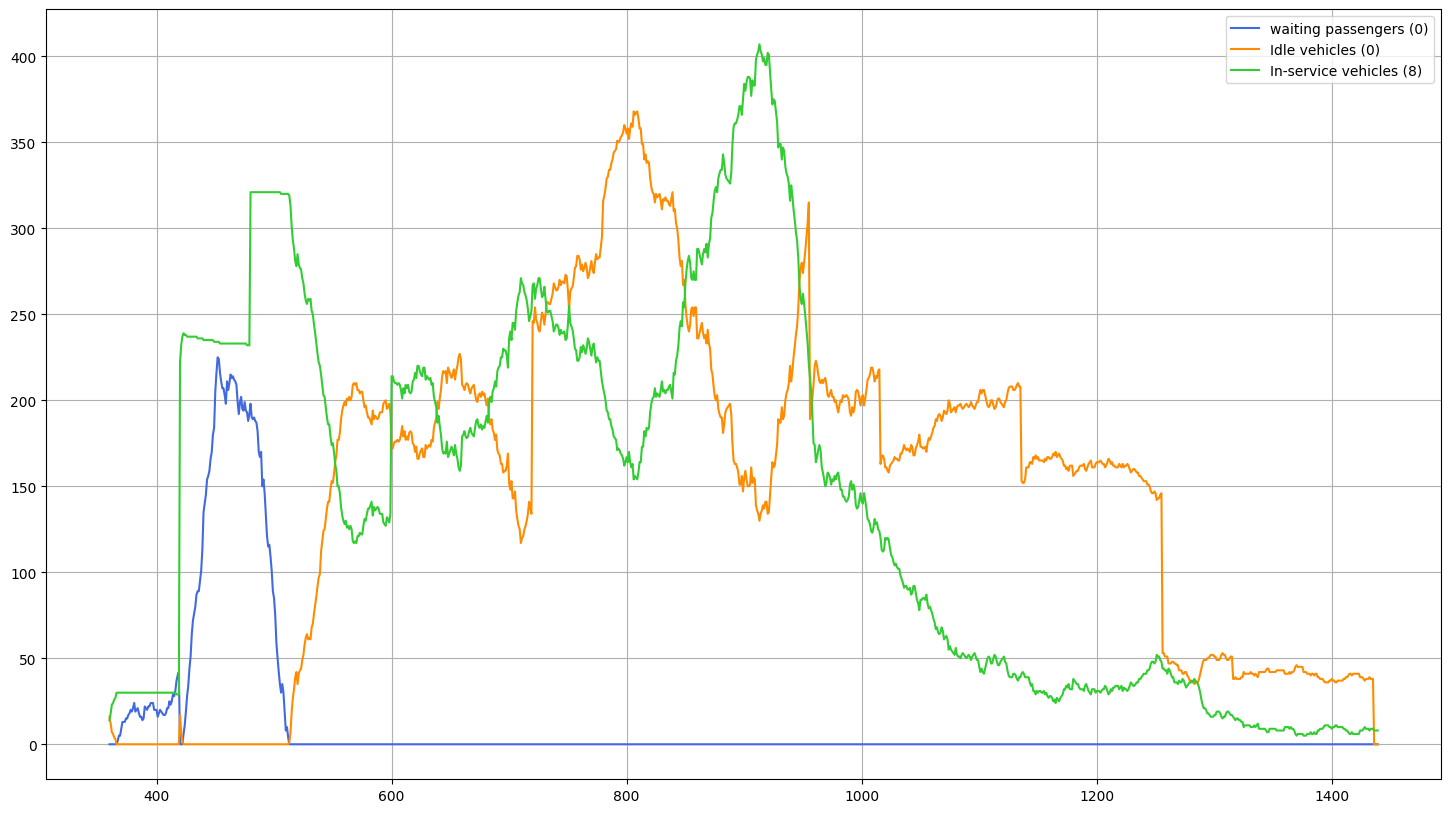

100%|██████████| 1080/1080 [05:23<00:00,  3.34it/s]


[Simulator] Saving simulation results to /Users/august/Documents/Projects/urban_mobility_digital_twin/thirdparty/dtumos/data/agents/simul_result/scenario_base/simulation_22/simulation_1
[Simulator] Simulation completed and results saved successfully!


In [ ]:
RUN_PIPELINE = True  # set True to execute end-to-end (will run simulation)
MAX_ROUNDS = 3
TEMPERATURE = 0.0

def run_experiment(state: SimulationState, max_rounds: int = 3, temperature: float = 0.0, run_id: str | None = None, export_dir: Path = EXPORT_DIR):
    state.conversation.clear()
    history = []
    run_id = run_id or datetime.utcnow().strftime("%Y%m%dT%H%M%S")
    baseline_snapshot: Dict[str, Any] | None = None
    for i in range(max_rounds):
        append_conv(state, "system", f"--- Round {i+1} ---")
        result = run_baseline_round(state, temperature=temperature)
        snapshot = summarize_round(result, state)
        if baseline_snapshot is None:
            baseline_snapshot = {
                "passengers": snapshot.get("passengers", 0),
                "vehicles": snapshot.get("vehicles", 0),
                "analysis": snapshot.get("analysis", {}),
                "configs": snapshot.get("configs", {}),
            }
        export_path = export_round(i, result, state, baseline_snapshot, run_id, export_dir)
        history.append({**result, "round_summary": snapshot, "export_path": export_path})
        orch = result.get("orchestrator", {})
        approve = orch.get("approve_rerun", False) if isinstance(orch, dict) else False
        next_action = orch.get("next_action") if isinstance(orch, dict) else None
        stop = orch.get("stop", False) if isinstance(orch, dict) else False
        if stop:
            break
        if next_action == "rerun":
            approve = True
        if not approve:
            break
    return history

if RUN_PIPELINE:
    history = run_experiment(state, max_rounds=MAX_ROUNDS, temperature=TEMPERATURE)
    results = history[-1] if history else {}
    history
else:
    print("Pipeline scaffold ready. Set RUN_PIPELINE=True to execute.")

In [10]:
# Display full agent conversation and plans
from pprint import pprint
import textwrap
print('\n=== Agent Plans (last round) ===')
try:
    pprint(results)
except NameError:
    print('No results available. Run the pipeline first.')
print('\n=== Conversation Log (structured outputs) ===')
if not state.conversation:
    print('No conversation captured. Run the pipeline first.')
else:
    for turn in state.conversation:
        role = turn.get('role','agent')
        content = turn.get('content','')
        print(f"\n[{role}]\n{content}")
print('\nDone.')


=== Agent Plans (last round) ===
{'analysis': {'avg_waiting': None,
              'failures': 410,
              'passenger_markers': 410,
              'trip_count': 5521,
              'waiting_peak': 225},
 'curator': {'dispatch_mode': 'greedy',
             'matrix_mode': 'street_distance',
             'passengers': 6002,
             'time_range': [360, 1440],
             'vehicles': 613},
 'intervention': {'configs_patch': {'demand_scaling': 1.2,
                                    'dispatch_mode': 'optimal',
                                    'fleet_size': 800,
                                    'routing_mode': 'traffic_aware'}},
 'orchestrator': {'approve_rerun': False,
                  'next_action': 'rerun',
                  'notes': 'Rerunning simulation with updated configs and last '
                           'results',
                  'stop': False},
 'simulation': {'save_path': '/Users/august/Documents/Projects/urban_mobility_digital_twin/thirdparty/dtumos/data